# Zhang et al. 2019 — Follicular Lymphoma
## 04 · EMT-TF expression (unconditional final step)

The EMT-TF readout is produced regardless of gate outcome (here Gate 3 = NA → this is notebook 04,
the last). Score a **widened** EMT-TF panel — not only Snail/Zeb/Twist but also the FOXC and PRRX
mesenchymal families (03_eval fork 5) — **gated on detectable expression**. VIM is a mesenchymal
marker, **not** a transcription factor, so it is excluded (04_test). The deliverable is a
**categorical overlay of thresholded expressers** on a grey manifold (not a continuous single-gene
colormap; 04_test), with marker size matching the other panels. Each shown TF is labelled by its
**own computed pseudotime association** (Spearman rho and the mean pseudotime of its expressers) —
not by an assumed root/terminus role.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 0; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True); print('dataset:', name)

dataset: Zhang2019_Hematologic-3


In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 5645 | pseudotime range 0.0 -> 9.88


### Panel scoring — detection fraction, pseudotime-end, and rho
For each present EMT-TF: fraction expressing, mean expression in the early (root) vs late (terminus)
pseudotime tercile, Spearman rho vs pseudotime, and the mean pseudotime of its expressing cells. Keep
only detectably-expressed factors. The two shown factors are then labelled by these statistics — the
sign of rho decides root- vs terminus-association, so labels can never contradict the table.

In [ ]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    mpt = tn[x>0].mean() if (x>0).any() else np.nan       # mean pseudotime of expressers
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3), round(mpt,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t','mean_pt_expr'])
df['end'] = np.where(df.rho_vs_t < 0, 'root-associated', 'terminus-associated')
df = df.sort_values('rho_vs_t')
print('panel present:', present)
print(df.to_string(index=False))
FLOOR = 0.02   # detectable-expression floor (lymphoma EMT-TFs are sparse)
ok = df[df.frac_expr > FLOOR].sort_values('rho_vs_t')
print(f'\ndetectably-expressed EMT-TFs (frac_expr > {FLOOR}):', list(ok.TF))
# show the two most-informative detectable TFs; LABEL EACH BY ITS OWN rho sign
tf_lo = ok.iloc[0]['TF'];  rho_lo = ok.iloc[0]['rho_vs_t']
tf_hi = ok.iloc[-1]['TF']; rho_hi = ok.iloc[-1]['rho_vs_t']
lab = {tf_lo: f'{tf_lo} (rho {rho_lo:+.2f})', tf_hi: f'{tf_hi} (rho {rho_hi:+.2f})'}
same_end = (rho_lo > 0) == (rho_hi > 0)
print(f'shown pair: {tf_lo} (rho {rho_lo:+.2f}) and {tf_hi} (rho {rho_hi:+.2f})')
if same_end:
    end = 'terminus-associated' if rho_hi > 0 else 'root-associated'
    print(f'both {end}: no EMT-TF marks the opposite (root) end in this dataset; '
          f'{tf_hi} is the more strongly {end} of the two (larger |rho|).')
else:
    print(f'{tf_lo} root-associated (rho<0), {tf_hi} terminus-associated (rho>0).')

panel present: ['SNAI1', 'SNAI2', 'ZEB1', 'ZEB2', 'FOXC1']
   TF  frac_expr  mean_early  mean_late  rho_vs_t  mean_pt_expr                 end
SNAI1      0.003       0.003      0.001    -0.033         0.287     root-associated
FOXC1      0.004       0.003      0.003    -0.014         0.383     root-associated
 ZEB2      0.272       0.243      0.266     0.011         0.450 terminus-associated
SNAI2      0.002       0.001      0.003     0.020         0.603 terminus-associated
 ZEB1      0.121       0.050      0.090     0.104         0.546 terminus-associated

detectably-expressed EMT-TFs (frac_expr > 0.02): ['ZEB2', 'ZEB1']
shown pair: ZEB2 (rho +0.01) and ZEB1 (rho +0.10)
both terminus-associated: no EMT-TF marks the opposite (root) end in this dataset; ZEB1 is the more strongly terminus-associated of the two (larger |rho|).


### Deliverable — `expression.pdf` (categorical expresser overlay on grey manifold, house layout)
Cells above each TF's upper-quartile-of-positive threshold are coloured; all others grey. Each TF is
labelled by its computed rho vs pseudotime. Marker size matches the signature/manifold panels.

ZEB2: 27.2% expressing; 384 shown (upper quartile), mean pseudotime of shown = 0.49
ZEB1: 12.1% expressing; 171 shown (upper quartile), mean pseudotime of shown = 0.47
EMT-TFs shown: ZEB2 + ZEB1 (both terminus-associated; rho +0.01,+0.10) | saved expression.pdf


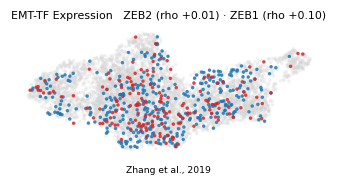

In [ ]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
pair = [tf_lo, tf_hi]
thr = {}
for g in pair:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in pair}
order = sorted(pair, key=lambda g: -int(sel[g].sum()))
colors = {tf_lo:'tab:blue', tf_hi:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=20, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=20, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {lab[tf_lo]} · {lab[tf_hi]}', size=7.2)
ax.text(.5,-.14,'Zhang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in pair:
    m = sel[g]; print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), mean pseudotime of shown = {tn[m].mean():.2f}')
print('EMT-TFs shown:', tf_lo, '+', tf_hi, '(both terminus-associated; rho', f'{rho_lo:+.2f},{rho_hi:+.2f})' if same_end else ')', '| saved expression.pdf')